# 02 – Document splits, token alignment, and distribution shift

The fixed document manifests define Train and Validation. Text and annotations from the historical test are not used in this analysis.

In [1]:
from pathlib import Path
from typing import Iterable, Sequence
from collections import Counter
from itertools import combinations
import json
import math
import re
import sys
import textwrap
import unicodedata
import xml.etree.ElementTree as ET
import joblib
import torch
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import entropy
from scipy.spatial.distance import jensenshannon
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
from matplotlib_inline.backend_inline import set_matplotlib_formats

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for _folder in ("artifacts", "figures/PNG", "figures/PDF", "Models", "Predictions", "Reports"):
    (PROJECT_ROOT / _folder).mkdir(parents=True, exist_ok=True)    # output folders of a fresh clone
SHARED_DATASET = PROJECT_ROOT / "dataset"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from core import ENTITY_TYPES, PREDICTION_COLUMNS
from analysis_tools import MODELS, FOCAL

BLUE, GOLD, INK = "#315C80", "#B47A19", "#252525"

In [3]:
set_matplotlib_formats("png", bbox_inches=None)
plt.ioff()
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("styler.render.max_elements", 100000)
mpl.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 18,
        "axes.titlesize": 20,
        "figure.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#333333",
        "text.color": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#333333",
        "ytick.color": "#333333",
        "axes.grid": False,
    }
)
assert "Times New Roman" in mpl.font_manager.findfont(
    "Times New Roman", fallback_to_default=False
)

In [4]:
def format_number(value: float, precision: int) -> str:
    """Format the display only; scientific values in exported CSV remain unchanged."""
    if pd.isna(value):
        return "N/A"
    if value != 0 and abs(value) < 0.5 * 10 ** (-precision):
        return f"{value:.2e}".replace("-", "−")
    if abs(value) < 0.5 * 10 ** (-precision):
        return "0" if precision == 0 else "0." + "0" * precision
    return f"{value:.{precision}f}".replace("-", "−")

In [5]:
def shared_root(project_root: Path) -> Path:
    root = (project_root / "dataset").resolve()
    if not (root / "Raw" / "ACQUISITION.json").exists():
        raise RuntimeError("Immutable shared dataset acquisition is missing.")
    return root

In [6]:
def load_processed(
    project_root: Path, split: str
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    shared = shared_root(project_root)
    sentences = pd.read_parquet(shared / "Processed" / f"{split}_sentences.parquet")
    entities = pd.read_parquet(shared / "Processed" / f"{split}_entities.parquet")
    tokens = pd.read_parquet(shared / "Processed" / f"{split}_tokens.parquet")
    return (sentences, entities, tokens)

In [7]:
train_s, train_e, train_t = load_processed(PROJECT_ROOT, "train")
valid_s, valid_e, valid_t = load_processed(PROJECT_ROOT, "validation")

## Document separation

**Scientific question.** Do any document IDs occur in more than one split?

In [8]:
manifests = {
    s: pd.read_csv(SHARED_DATASET / "Splits" / f"{s}_documents.csv")
    for s in ("train", "validation", "locked_test")
}
assert all(
    (
        set(manifests[a].document_id).isdisjoint(manifests[b].document_id)
        for a, b in combinations(manifests, 2)
    )
)
split_counts = pd.concat(
    [
        f.groupby("source").size().rename("Documents").reset_index().assign(Split=s)
        for s, f in manifests.items()
    ]
)
result_table = split_counts[["Split", "source", "Documents"]].copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_02_splits.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 0)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,source,Documents
train,DrugBank,458
train,MedLine,114
validation,DrugBank,114
validation,MedLine,28
locked_test,DrugBank,54
locked_test,MedLine,58


The split manifests are disjoint at document-ID level.

Train: 572; Validation: 142; historical test: 112 documents.

This prevents an individual document from entering multiple partitions.

**Scope.** Exact shared text across different IDs is assessed in Notebook 01.

## Eligibility and alignment

**Scientific question.** Why do raw annotation counts differ from the scoring denominator?

In [9]:
def gold_for_metrics(entities: pd.DataFrame) -> pd.DataFrame:
    return entities.query("not discontinuous and offset_valid").copy()

In [10]:
eligibility = pd.DataFrame(
    [
        {
            "Split": s,
            "Raw entities": len(e),
            "Discontinuous excluded": int(e.discontinuous.sum()),
            "Strict gold N": len(gold_for_metrics(e)),
        }
        for s, e in [("Train", train_e), ("Validation", valid_e)]
    ]
)
result_table = eligibility.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_02_eligibility.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 0)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,Raw entities,Discontinuous excluded,Strict gold N
Train,11841,29,11812
Validation,2924,9,2915


The denominator difference comes from discontinuous spans, not different samples.

Validation: 2,924 annotations − 9 discontinuous = 2,915 eligible gold spans.

All models must use the same eligible gold entity set.

**Scope.** WordPiece projection can still prevent exact recovery of some contiguous spans.

## Offset fidelity

**Scientific question.** What proportion of targets can be represented exactly by the saved tokenizer?

In [11]:
alignment_observations = []
for split, entities, token_frame in [
    ("Train", train_e, train_t),
    ("Validation", valid_e, valid_t),
]:
    token_groups = dict(tuple(token_frame.groupby("sentence_id")))
    for entity in entities.itertuples():
        sequence = token_groups[entity.sentence_id]
        hits = sequence[
            (sequence.char_start < entity.char_end) & (sequence.char_end > entity.char_start)
        ]
        if entity.discontinuous:
            status = "Discontinuous: excluded"
        elif not entity.offset_valid:
            status = "Invalid offsets: excluded"
        elif hits.empty:
            status = "No overlapping token"
        elif (
            hits.char_start.min() == entity.char_start
            and hits.char_end.max() == entity.char_end
        ):
            status = "Exact tokenizer edges"
        else:
            status = "Non-exact tokenizer edges"
        alignment_observations.append({"Split": split, "Status": status})
alignment = pd.DataFrame(alignment_observations).value_counts().rename("N").reset_index()
alignment["Within-split share"] = alignment.N / alignment.groupby("Split").N.transform("sum")
result_table = alignment.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_02_alignment.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,Status,N,Within-split share
Train,Exact tokenizer edges,11791,0.9958
Validation,Exact tokenizer edges,2906,0.9938
Train,Discontinuous: excluded,29,0.0024
Train,Non-exact tokenizer edges,21,0.0018
Validation,Discontinuous: excluded,9,0.0031
Validation,Non-exact tokenizer edges,9,0.0031


Alignment statuses expose representational limits rather than silently repairing gold.

Every alignment category and its within-split fraction is displayed.

Character offsets remain authoritative at evaluation and handoff.

**Scope.** Non-exact alignment is an upper-bound limitation of the selected tokenizer.

## Sequence imbalance

**Scientific question.** How much of each sequence belongs to the dominant O class?

In [12]:
balance = pd.concat(
    [t.assign(Split=s) for s, t in [("Train", train_t), ("Validation", valid_t)]]
)
balance["Target"] = np.where(balance.boundary_tag.eq("O"), "O", "Entity token")
counts = balance.groupby(["Split", "Target"]).size().rename("Tokens").reset_index()
counts["Share"] = counts.Tokens / counts.groupby("Split").Tokens.transform("sum")
result_table = counts.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_token_imbalance.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,Target,Tokens,Share
Train,Entity token,27432,0.1934
Train,O,114442,0.8066
Validation,Entity token,6685,0.1956
Validation,O,27500,0.8044


The O class dominates token-level supervision.

Two target groups are counted separately for Train and Validation.

High token accuracy can coexist with poor entity retrieval.

**Scope.** Binary grouping suppresses BIOES transition detail.

## Training-only lexical evidence

**Scientific question.** How much of Validation is covered by the Train vocabulary?

In [13]:
def normalize_surface(text: str) -> str:
    normalized = unicodedata.normalize("NFKC", text).lower().strip()
    normalized = re.sub("[‐‑‒–—−]", "-", normalized)
    normalized = re.sub("\\s+", " ", normalized)
    return normalized

In [14]:
vocabulary = set(gold_for_metrics(train_e).entity_text.map(normalize_surface))
validation_gold = gold_for_metrics(valid_e).copy()
validation_gold["Seen"] = validation_gold.entity_text.map(normalize_surface).isin(vocabulary)
overlap = (
    validation_gold.groupby("entity_type")
    .agg(N=("entity_id", "size"), Seen=("Seen", "sum"))
    .reset_index()
)
overlap["Unseen"] = overlap.N - overlap.Seen
overlap["Seen share"] = overlap.Seen / overlap.N
result_table = overlap.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_lexical_coverage.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

entity_type,N,Seen,Unseen,Seen share
brand,283,92,191,0.3251
drug,1858,1537,321,0.8272
drug_n,103,25,78,0.2427
group,671,553,118,0.8241


Lexical coverage differs by subtype.

The four subtype denominators sum to 2,915 eligible Validation entities.

Seen/unseen evaluation separates repetition from lexical generalization.

**Scope.** A seen surface can still require context-dependent typing.

## Feature–target association

**Scientific question.** Which training descriptors are associated with entity tokens?

In [15]:
def holm(values):
    p = np.asarray(values)
    order = np.argsort(p)
    result = np.zeros(len(p))
    result[order] = np.minimum(
        1, np.maximum.accumulate(p[order] * (len(p) - np.arange(len(p))))
    )
    return result

In [16]:
training_features = train_t[["document_id", "surface_text", "boundary_tag"]].copy()
training_features["Entity token"] = training_features.boundary_tag.ne("O").astype(float)
training_features["Capitalized"] = training_features.surface_text.str.match("^[A-Z]").astype(
    float
)
training_features["Digit present"] = training_features.surface_text.str.contains("\\d").astype(
    float
)
training_features["Hyphen present"] = training_features.surface_text.str.contains(
    "-", regex=False
).astype(float)
training_features["Token characters"] = training_features.surface_text.str.len().astype(float)
descriptors = ["Capitalized", "Digit present", "Hyphen present", "Token characters"]
document_features = training_features.groupby("document_id")[
    ["Entity token"] + descriptors
].mean()
association_rows = []
for descriptor in descriptors:
    result = stats.spearmanr(document_features[descriptor], document_features["Entity token"])
    association_rows.append(
        {
            "Feature": descriptor,
            "Train documents": len(document_features),
            "Spearman rho": result.statistic,
            "p-value": result.pvalue,
        }
    )
association = pd.DataFrame(association_rows)
association["Holm p-value"] = holm(association["p-value"])
result_table = association.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_feature_association.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Feature,Train documents,Spearman rho,p-value,Holm p-value
Capitalized,572,0.0170,0.6854,1.0000
Digit present,572,−0.1903,4.59e−06,1.38e−05
Hyphen present,572,0.0088,0.8332,1.0000
Token characters,572,−0.2259,4.70e−08,1.88e−07


**Finding.** The table reports four recalculated document-level associations.

Spearman correlations relate within-document mean orthographic descriptors to entity-token share.

**Scope.** Descriptive, not causal; document source may confound the association. Holm corrects four comparisons.

## Development shift

**Scientific question.** How do sentence structure and target proportions change across development partitions?

In [17]:
development_sentences = pd.concat([train_s, valid_s], ignore_index=True)
development_sentences["Words"] = development_sentences.text.map(
    lambda text: len(re.findall("\\w+|[^\\w\\s]", text))
)
development_gold = gold_for_metrics(pd.concat([train_e, valid_e], ignore_index=True))
development_sentences["Entities"] = development_sentences.sentence_id.map(
    development_gold.groupby("sentence_id").size()
).fillna(0)
document_structure = development_sentences.groupby(
    ["document_id", "split"], as_index=False
).agg(Sentence_words=("Words", "mean"), Sentence_entities=("Entities", "mean"))
shift_rows = []
for descriptor in ["Sentence_words", "Sentence_entities"]:
    left = document_structure.loc[document_structure.split.eq("train"), descriptor].to_numpy()
    right = document_structure.loc[
        document_structure.split.eq("validation"), descriptor
    ].to_numpy()
    pooled_sd = np.sqrt((left.var(ddof=1) + right.var(ddof=1)) / 2)
    shift_rows.append(
        {
            "Descriptor": descriptor.replace("_", " "),
            "Train N": len(left),
            "Validation N": len(right),
            "Train mean": left.mean(),
            "Validation mean": right.mean(),
            "Standardized difference": (right.mean() - left.mean()) / pooled_sd,
            "KS distance": stats.ks_2samp(left, right).statistic,
        }
    )
shift = pd.DataFrame(shift_rows)
result_table = shift.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_distribution_shift.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Descriptor,Train N,Validation N,Train mean,Validation mean,Standardized difference,KS distance
Sentence words,572,142,23.7046,22.8251,−0.0838,0.0723
Sentence entities,572,142,2.4188,2.2732,−0.0684,0.0806


**Finding.** Means, standardized differences and KS distances are recalculated over documents.

Positive standardized difference means a higher Validation mean.

**Scope.** Document size varies; the standardized difference uses the equally weighted group variances.

## Modeling schema

**Scientific question.** Which representations are available without target information at inference?

In [18]:
schema = pd.DataFrame(
    [
        ["Raw text + offsets", "Observed", "Frozen Transformer / CRF inputs"],
        ["Training lexicon", "Train-derived", "Reliability features only"],
        ["Source", "Observed when supplied", "Domain indicator"],
        ["Gold subtype / density", "Target-derived", "Analysis and training only"],
        ["Entity ID", "Deterministic", "Downstream alignment"],
    ],
    columns=["Field group", "Origin", "Permitted role"],
)
result_table = schema.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_inference_contract.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Field group,Origin,Permitted role
Raw text + offsets,Observed,Frozen Transformer / CRF inputs
Training lexicon,Train-derived,Reliability features only
Source,Observed when supplied,Domain indicator
Gold subtype / density,Target-derived,Analysis and training only
Entity ID,Deterministic,Downstream alignment


Feature origin determines whether it can be used at inference.

Five field groups separate observed inputs, Train-derived features, and targets.

The contract connects preprocessing to the downstream relation-extraction interface.

**Scope.** Source may be unavailable for an unseen deployment stream.

## WordPiece fragmentation

**Scientific question.** How much does biomedical entity spelling expand under the frozen tokenizer?

In [19]:
def wordpiece_fertility(entities, tokens):
    gold = gold_for_metrics(entities)
    groups = {s: t for s, t in tokens.groupby("sentence_id")}
    rows = []
    for r in gold.itertuples():
        t = groups[r.sentence_id]
        hits = t[(t.char_start < r.char_end) & (t.char_end > r.char_start)]
        lexical = max(1, len(re.findall("\\w+|[^\\w\\s]", r.entity_text)))
        rows.append(
            {
                "Split": r.split,
                "Type": r.entity_type,
                "Words": lexical,
                "WordPieces": len(hits),
                "Fertility": len(hits) / lexical,
                "Exact tokenizer edges": bool(
                    len(hits)
                    and hits.char_start.min() == r.char_start
                    and (hits.char_end.max() == r.char_end)
                ),
            }
        )
    f = pd.DataFrame(rows)
    return f.groupby(["Split", "Type"], as_index=False).agg(
        N=("Fertility", "size"),
        Mean_fertility=("Fertility", "mean"),
        P95_wordpieces=("WordPieces", lambda s: s.quantile(0.95)),
        Multi_piece_share=("WordPieces", lambda s: s.gt(1).mean()),
        Exact_edge_share=("Exact tokenizer edges", "mean"),
    )

In [20]:
all_entities = pd.concat([train_e, valid_e], ignore_index=True)
all_tokens = pd.concat([train_t, valid_t], ignore_index=True)
fertility = wordpiece_fertility(all_entities, all_tokens)
result_table = fertility.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_wordpiece_fertility.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,Type,N,Mean_fertility,P95_wordpieces,Multi_piece_share,Exact_edge_share
train,brand,1154,2.5963,4.0000,0.9090,1.0000
train,drug,7560,2.0239,5.0000,0.4997,0.9991
train,drug_n,400,2.0180,9.0000,0.8400,1.0000
train,group,2698,1.4498,5.0000,0.7231,0.9948
validation,brand,283,2.6985,4.0000,0.9187,1.0000
validation,drug,1858,2.0154,5.0000,0.5242,0.9978
validation,drug_n,103,1.7699,6.0000,0.6019,0.9903
validation,group,671,1.3458,5.0000,0.6632,0.9940


Tokenizer fragmentation differs across pharmacological types.

Mean fertility ranges from 1.346 to 2.698; highest in validation / brand. All eight strata retain their complete eligible gold denominators.

High fragmentation increases sequence length and can weaken exact boundary projection.

**Scope.** Regex words and WordPiece units are different; fertility is not linguistic morpheme count.

## Sequence transition structure

**Scientific question.** Which boundary transitions dominate training supervision?

In [21]:
def transition_profile(tokens):
    f = tokens.sort_values(["sentence_id", "token_index"])
    following = f.groupby("sentence_id").boundary_tag.shift(-1)
    counts = pd.crosstab(f.boundary_tag, following).reindex(
        index=["O", "B", "I", "E", "S"], columns=["O", "B", "I", "E", "S"], fill_value=0
    )
    counts.index.name = "Current tag"
    counts.columns.name = "Next tag"
    probability = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
    return probability.reset_index().melt(
        "Current tag", var_name="Next tag", value_name="Probability"
    )

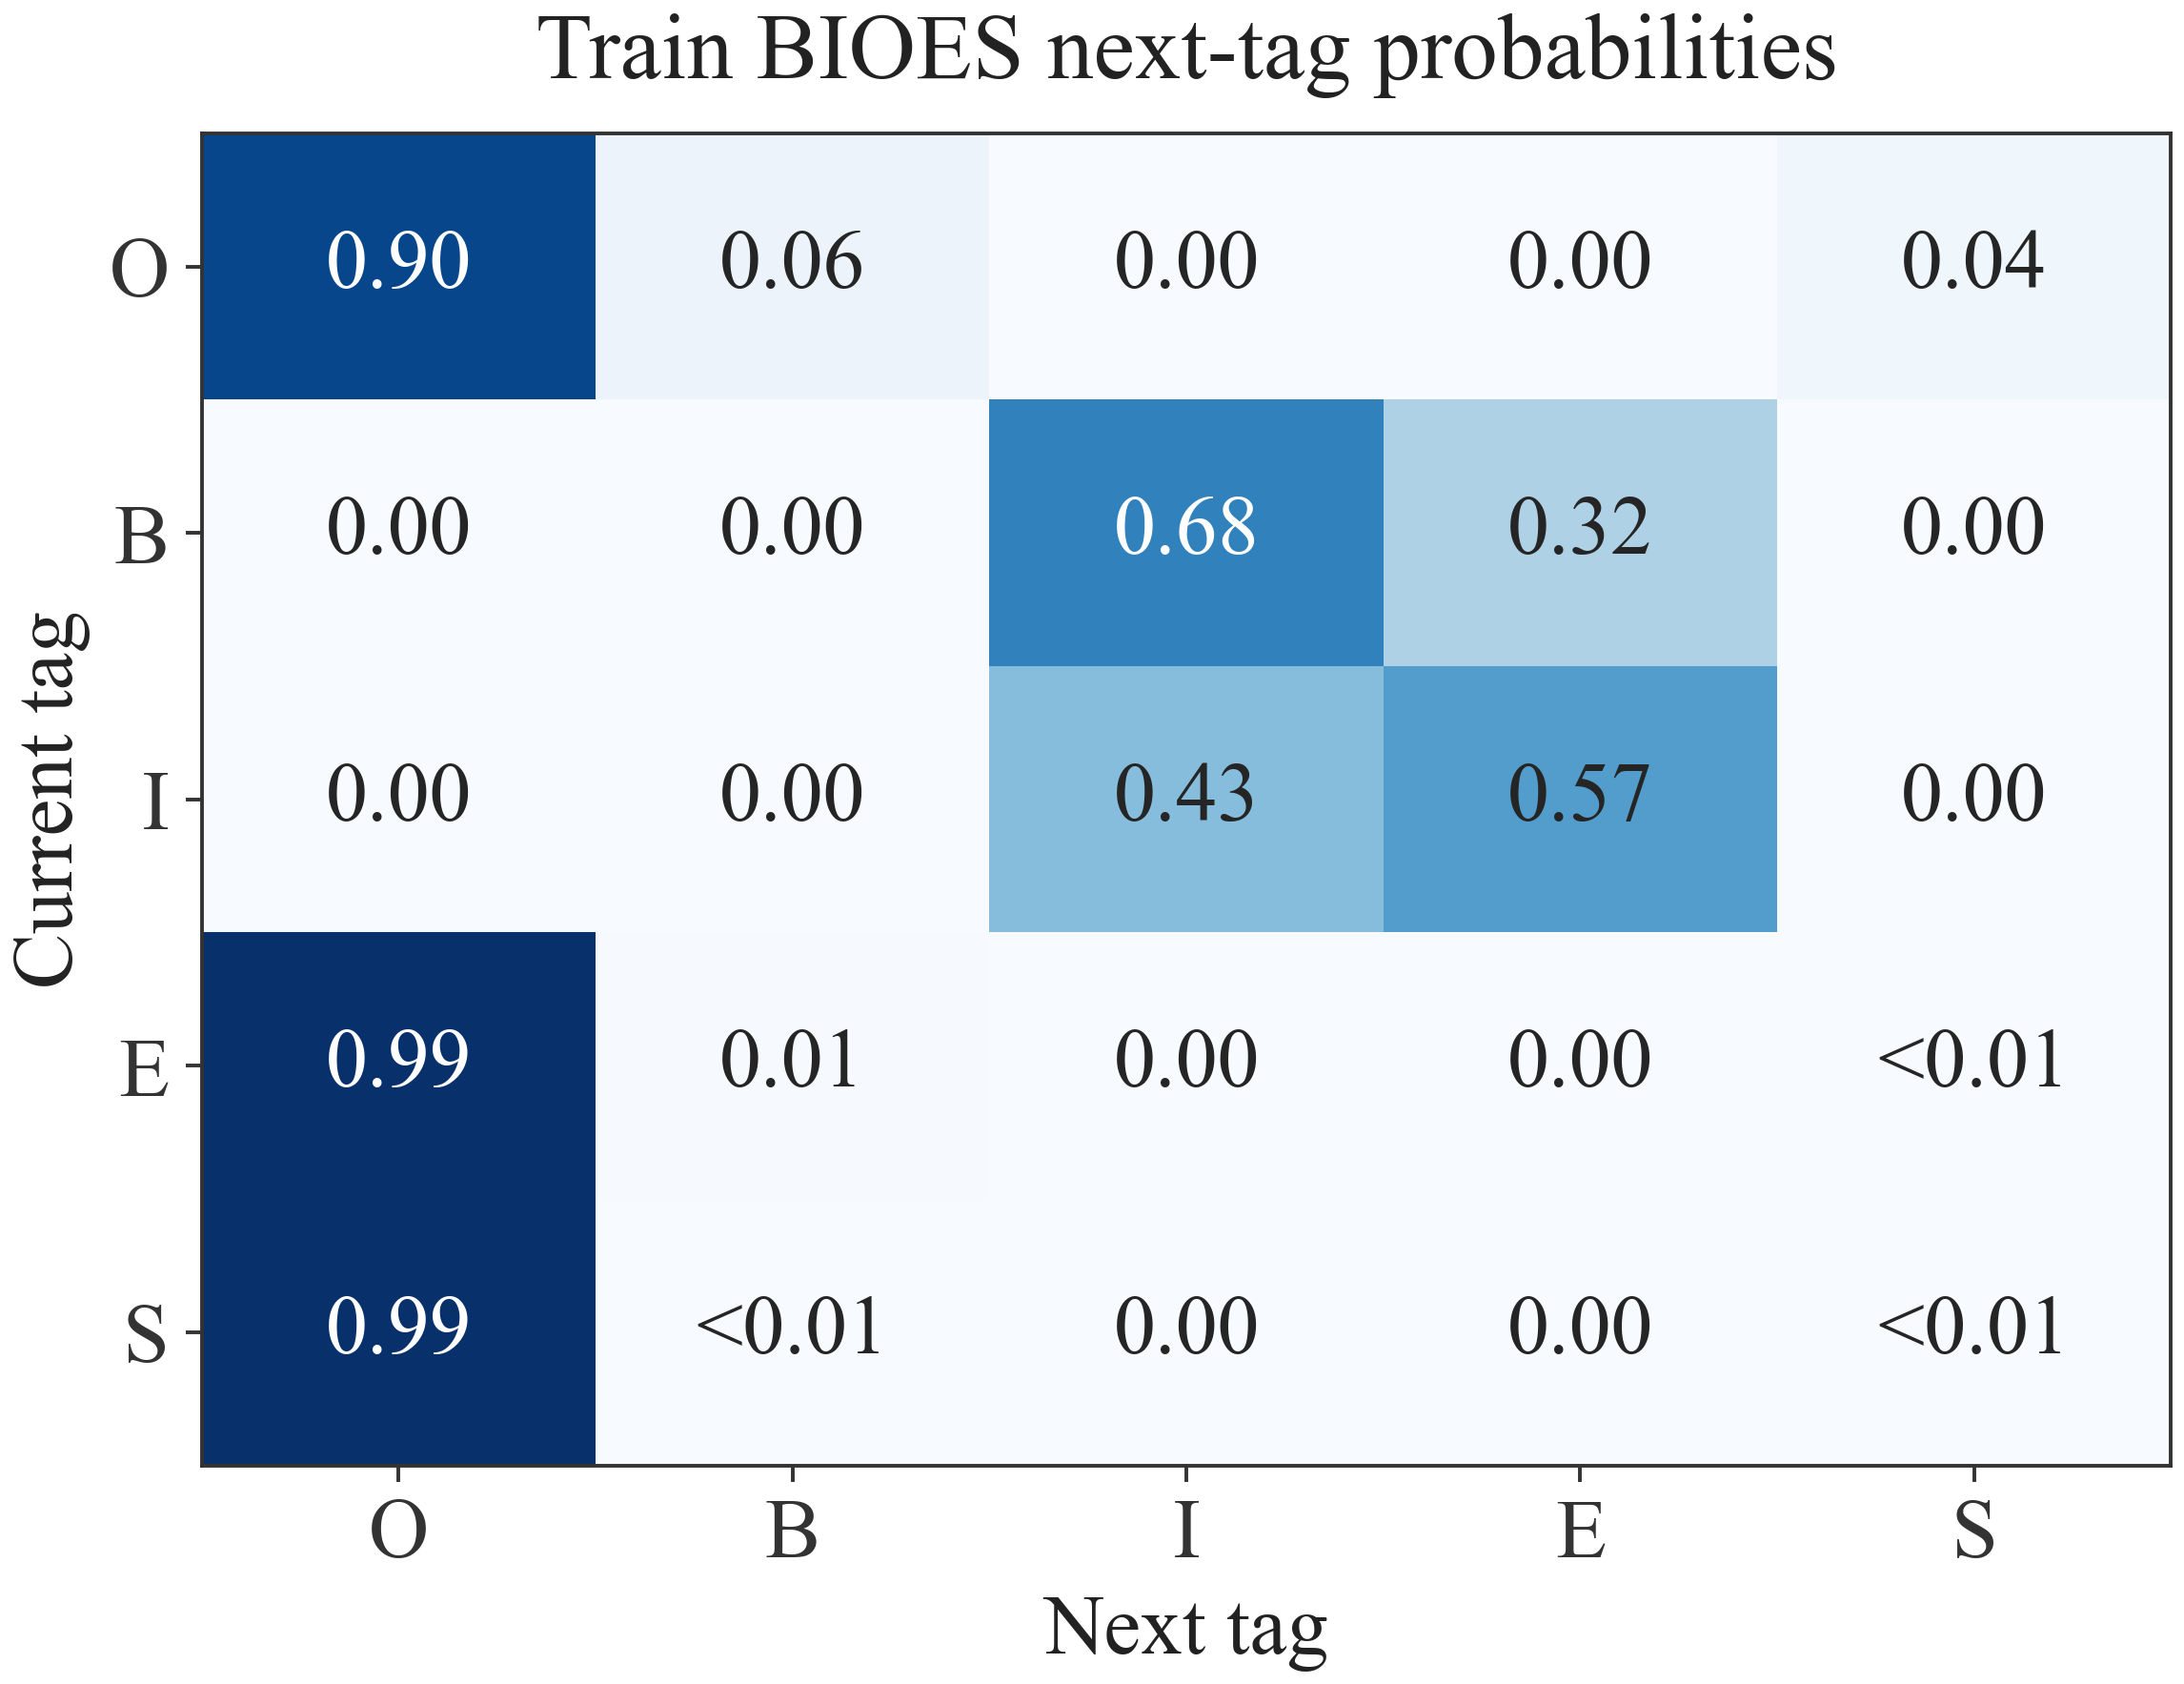

In [22]:
transitions = transition_profile(train_t)
plot_data = transitions.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.55, 5.05), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
matrix = plot_data.pivot(index="Current tag", columns="Next tag", values="Probability")
for axis in ("index", "columns"):
    labels = list(getattr(matrix, axis))
    order = (
        list(ENTITY_TYPES) + ["No exact span"]
        if set(ENTITY_TYPES) <= set(labels)
        else ["O", "B", "I", "E", "S"]
    )
    if set(labels) <= set(order):
        matrix = matrix.reindex(**{axis: [label for label in order if label in labels]})
values = matrix.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert not np.isinf(values).any()
signed = bool(len(finite) and finite.min() < 0)
colormap = mpl.colormaps["RdBu_r" if signed else "Blues"].copy()
colormap.set_bad("#E4E4E4")
heatmap = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=colormap,
    aspect="auto",
    **{"vmin": -1, "vmax": 1} if signed else {},
)
short_labels = {
    "Overlong": "Too\nlong",
    "Underlong": "Too\nshort",
    "Shifted overlap": "Shifted",
    "Wrong type": "Wrong\ntype",
}
ax.set_xticks(
    range(len(matrix.columns)),
    [short_labels.get(str(v), textwrap.fill(str(v), 11)) for v in matrix.columns],
)
ax.set_yticks(range(len(matrix)), [textwrap.fill(str(v), 16) for v in matrix.index])
for (row, column), value in np.ndenumerate(values):
    rgba = heatmap.cmap(heatmap.norm(value))
    luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    if not np.isfinite(value):
        annotation = "N/A"
    elif "Probability" == "Count":
        annotation = f"{value:,.0f}"
    elif 0 < abs(value) < 0.005:
        annotation = ">−0.01" if value < 0 else "<0.01"
    else:
        annotation = f"{value:.2f}".replace("-", "−")
    ax.text(
        column,
        row,
        annotation,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if np.isfinite(value) and luminance < 0.5 else INK,
    )
if np.isnan(values).any():
    assert "N/A: no observed outgoing transitions for this tag."
    fig.supxlabel(
        textwrap.fill("N/A: no observed outgoing transitions for this tag.", 52),
        fontsize=18,
        color=INK,
    )
ax.set_title("Train BIOES next-tag probabilities", fontsize=20, pad=12)
ax.set_xlabel("Next tag")
ax.set_ylabel("Current tag")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_02_transition_profile.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_02_transition_profile.pdf", dpi=350, facecolor="white"
)
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_02_transition_profile_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

Conditional next-tag probabilities reveal the actual sequential supervision available to the CRF.

A 5 × 5 transition matrix; transitions never cross sentence boundaries.

The distribution distinguishes dominant O persistence from multi-token entity continuation.

**Scope.** Zero means an unobserved transition with a positive row denominator; N/A would mean no observed outgoing transitions. Neither substitutes for an explicit constrained decoder.

## Text-neighbor dependence

**Scientific question.** How close is each Validation document to its nearest Train text?

In [23]:
def document_text_analysis(sentences, root=None):
    documents = (
        sentences.sort_values(["document_id", "sentence_index"])
        .groupby(["document_id", "split", "source"], as_index=False)
        .text.agg(" ".join)
    )
    train = documents.split.eq("train")
    valid = documents.split.eq("validation")
    vectorizer = TfidfVectorizer(
        analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=40000, sublinear_tf=True
    )
    xtrain = vectorizer.fit_transform(documents.loc[train, "text"])
    xvalid = vectorizer.transform(documents.loc[valid, "text"])
    similarity = linear_kernel(xvalid, xtrain)
    maximum = similarity.max(axis=1)
    nearest = documents.loc[valid, ["document_id", "source"]].copy()
    nearest["Nearest Train cosine"] = maximum
    nearest["Nearest Train document"] = documents.loc[train, "document_id"].to_numpy()[
        similarity.argmax(axis=1)
    ]
    svd = TruncatedSVD(n_components=2, random_state=20260905)
    train_xy = svd.fit_transform(xtrain)
    valid_xy = svd.transform(xvalid)
    projection = documents[["document_id", "split", "source"]].copy()
    projection.loc[train, ["SVD 1", "SVD 2"]] = train_xy
    projection.loc[valid, ["SVD 1", "SVD 2"]] = valid_xy
    projection["Group"] = projection.source + " / " + projection.split
    support = pd.DataFrame(
        [
            {
                "Train documents": int(train.sum()),
                "Validation documents": int(valid.sum()),
                "Train-fit n-grams": xtrain.shape[1],
                "Two-component variance share": svd.explained_variance_ratio_.sum(),
            }
        ]
    )
    if root is not None:
        directory = root / "Reports/Analysis"
        directory.mkdir(parents=True, exist_ok=True)
        path = directory / "train_text_projection.joblib"
        joblib.dump(
            {
                "vectorizer": vectorizer,
                "svd": svd,
                "train_ids": documents.loc[train, "document_id"].tolist(),
            },
            path,
        )
        restored = joblib.load(path)
        np.testing.assert_allclose(
            restored["svd"].transform(
                restored["vectorizer"].transform(documents.loc[valid, "text"])
            ),
            valid_xy,
        )
    return (nearest, projection, support)

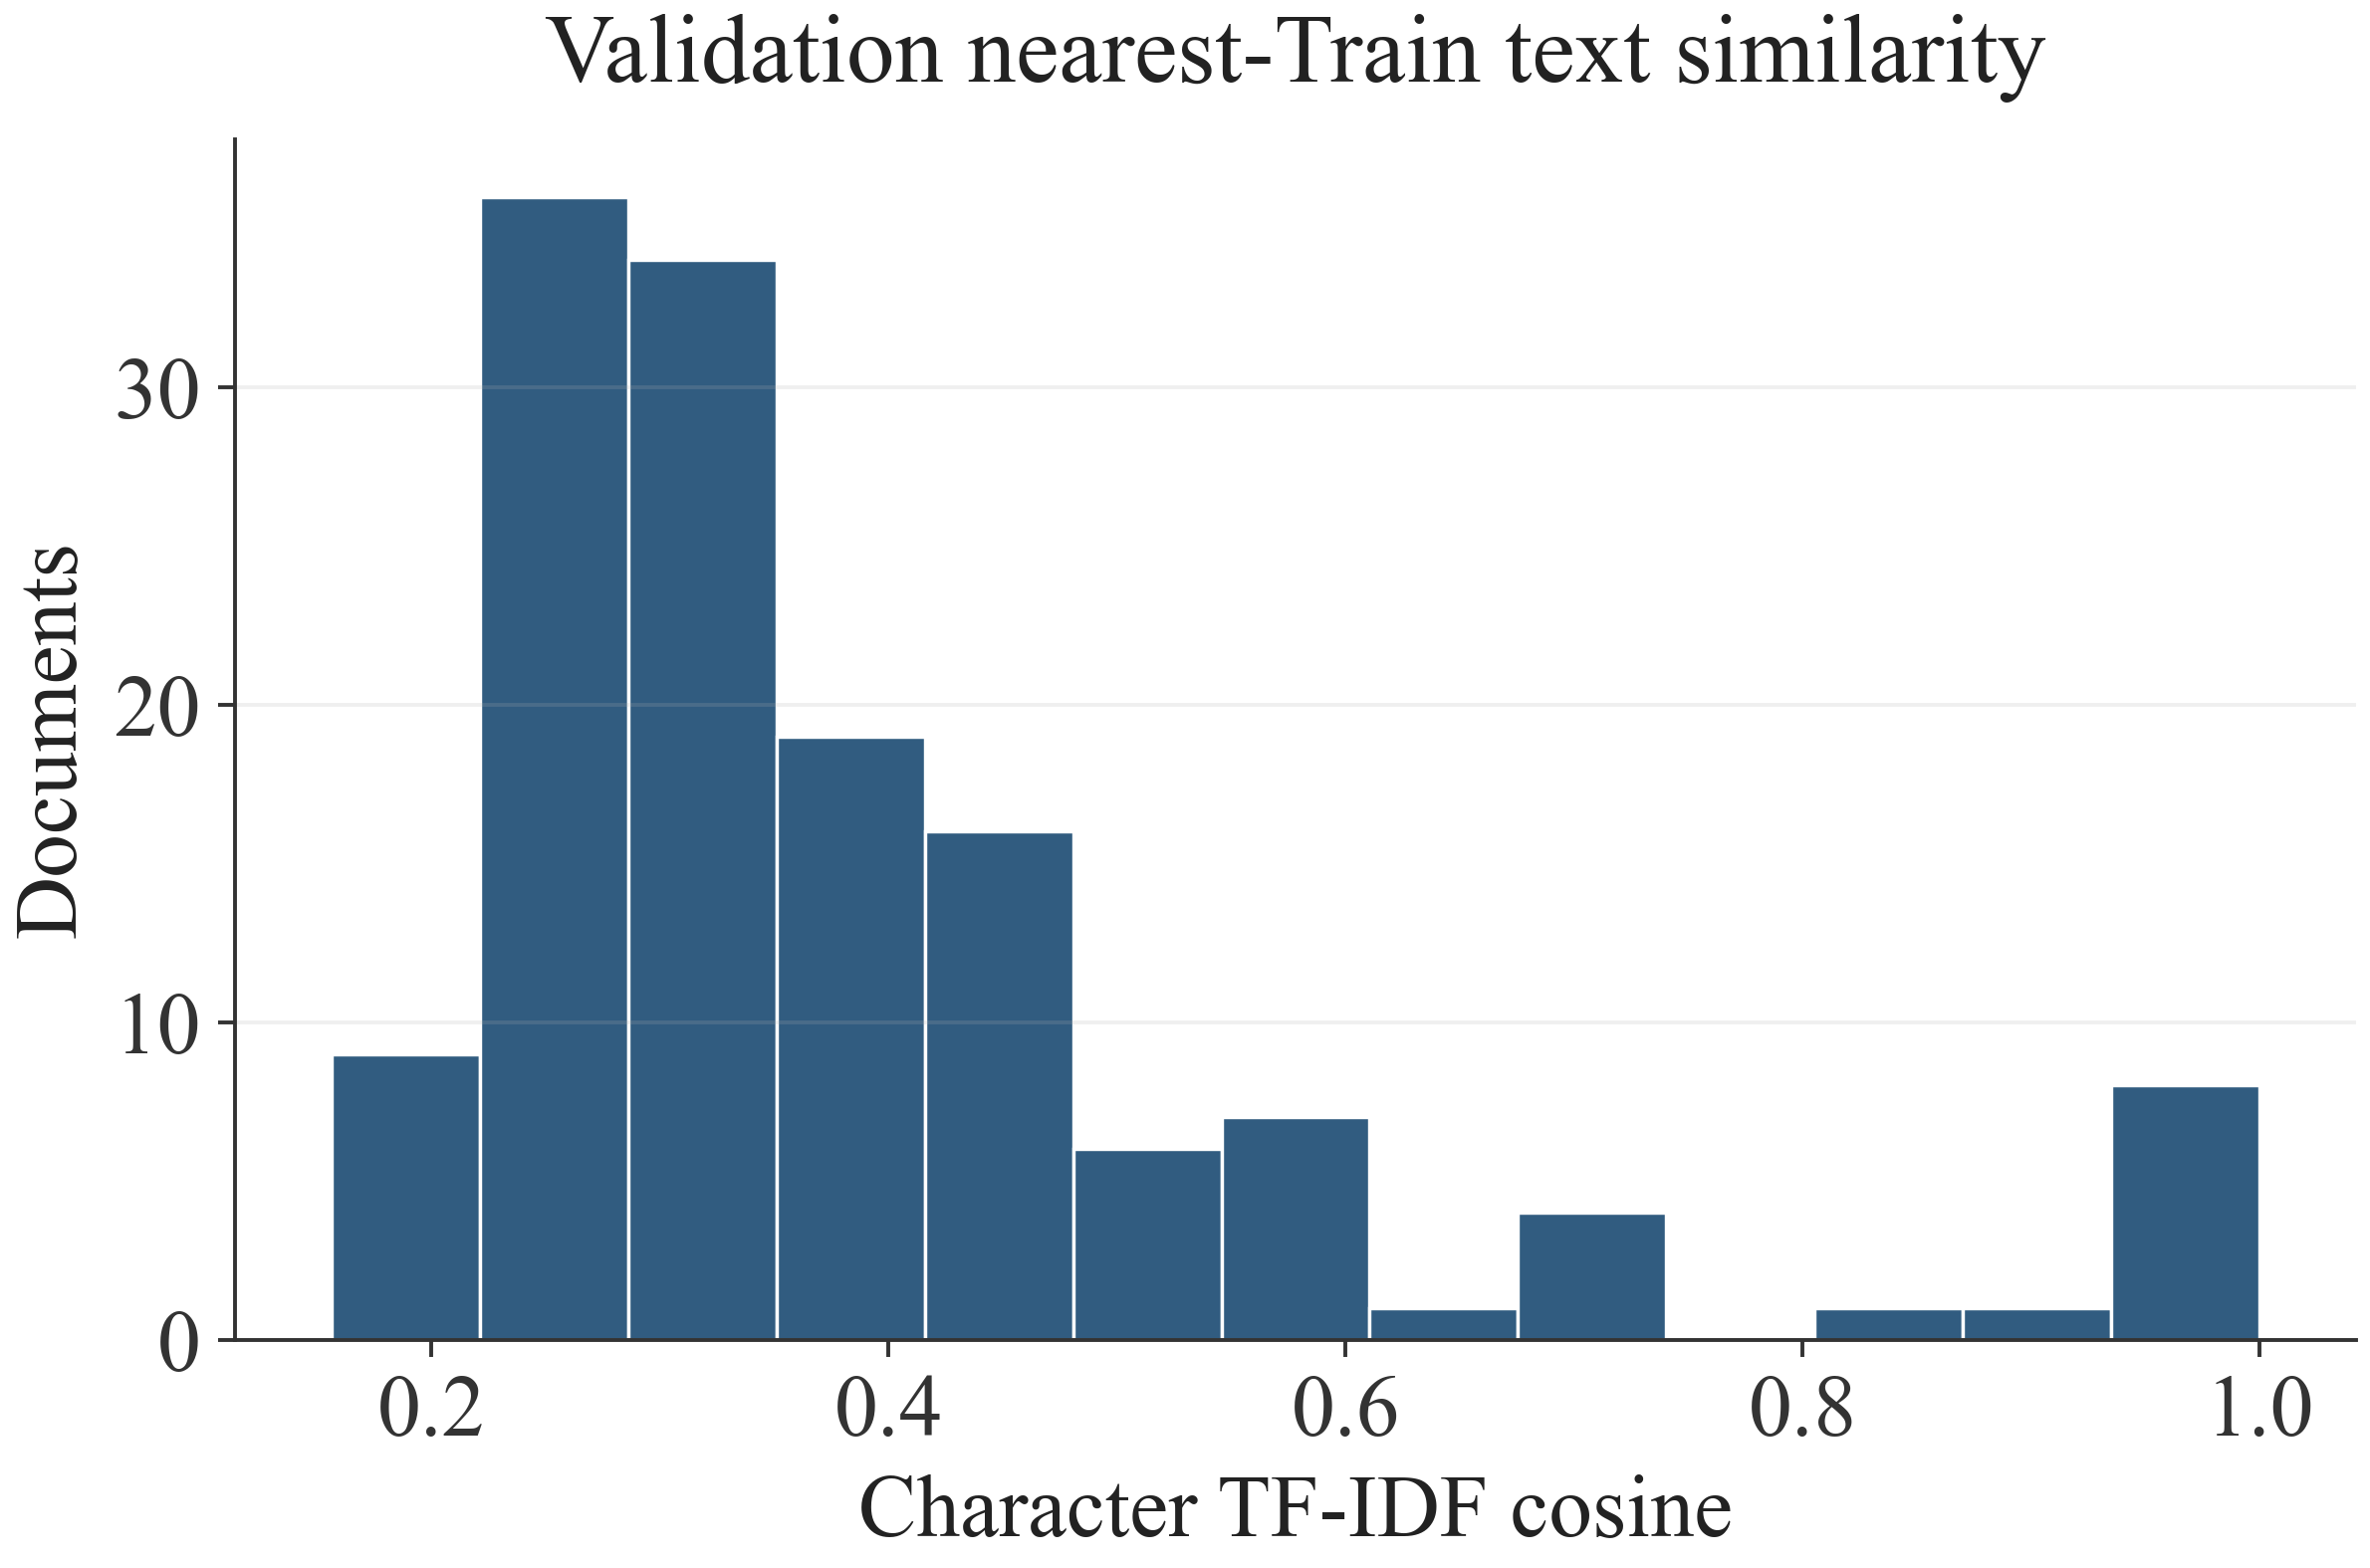

In [24]:
development_text = pd.concat([train_s, valid_s], ignore_index=True)
nearest, projection, projection_support = document_text_analysis(
    development_text, root=PROJECT_ROOT
)
plot_data = nearest.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.8, 4.5), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
ax.hist(
    plot_data["Nearest Train cosine"], bins="fd", color=BLUE, edgecolor="white", linewidth=0.7
)
if plot_data["Nearest Train cosine"].max() > 3 * plot_data["Nearest Train cosine"].quantile(
    0.75
):
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(
            lambda value, position: f"{value:,.0f}" if value >= 1 else f"{value:g}"
        )
    )
ax.set_title("Validation nearest-Train text similarity", fontsize=20, pad=12)
ax.set_xlabel("Character TF-IDF cosine")
ax.set_ylabel("Documents")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
if ax.get_yscale() == "log":
    ax.set_ylabel("Documents (log scale)")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(PROJECT_ROOT / "figures/PNG/pub_02_nearest_text.png", dpi=350, facecolor="white")
fig.savefig(PROJECT_ROOT / "figures/PDF/pub_02_nearest_text.pdf", dpi=350, facecolor="white")
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_02_nearest_text_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

Validation documents span a range of lexical similarity to the nearest Train document.

Median nearest cosine = 0.3244; 95th percentile = 0.9487; 10 of 142 documents reach 0.80.

High similarity is potential textual dependence, not proof of duplicated annotations or semantic equivalence.

**Scope.** Character n-grams detect lexical resemblance and can be high for shared domain terminology.

## Train-fitted text geometry

**Scientific question.** Do source and split populations occupy different regions in a fixed lexical projection?

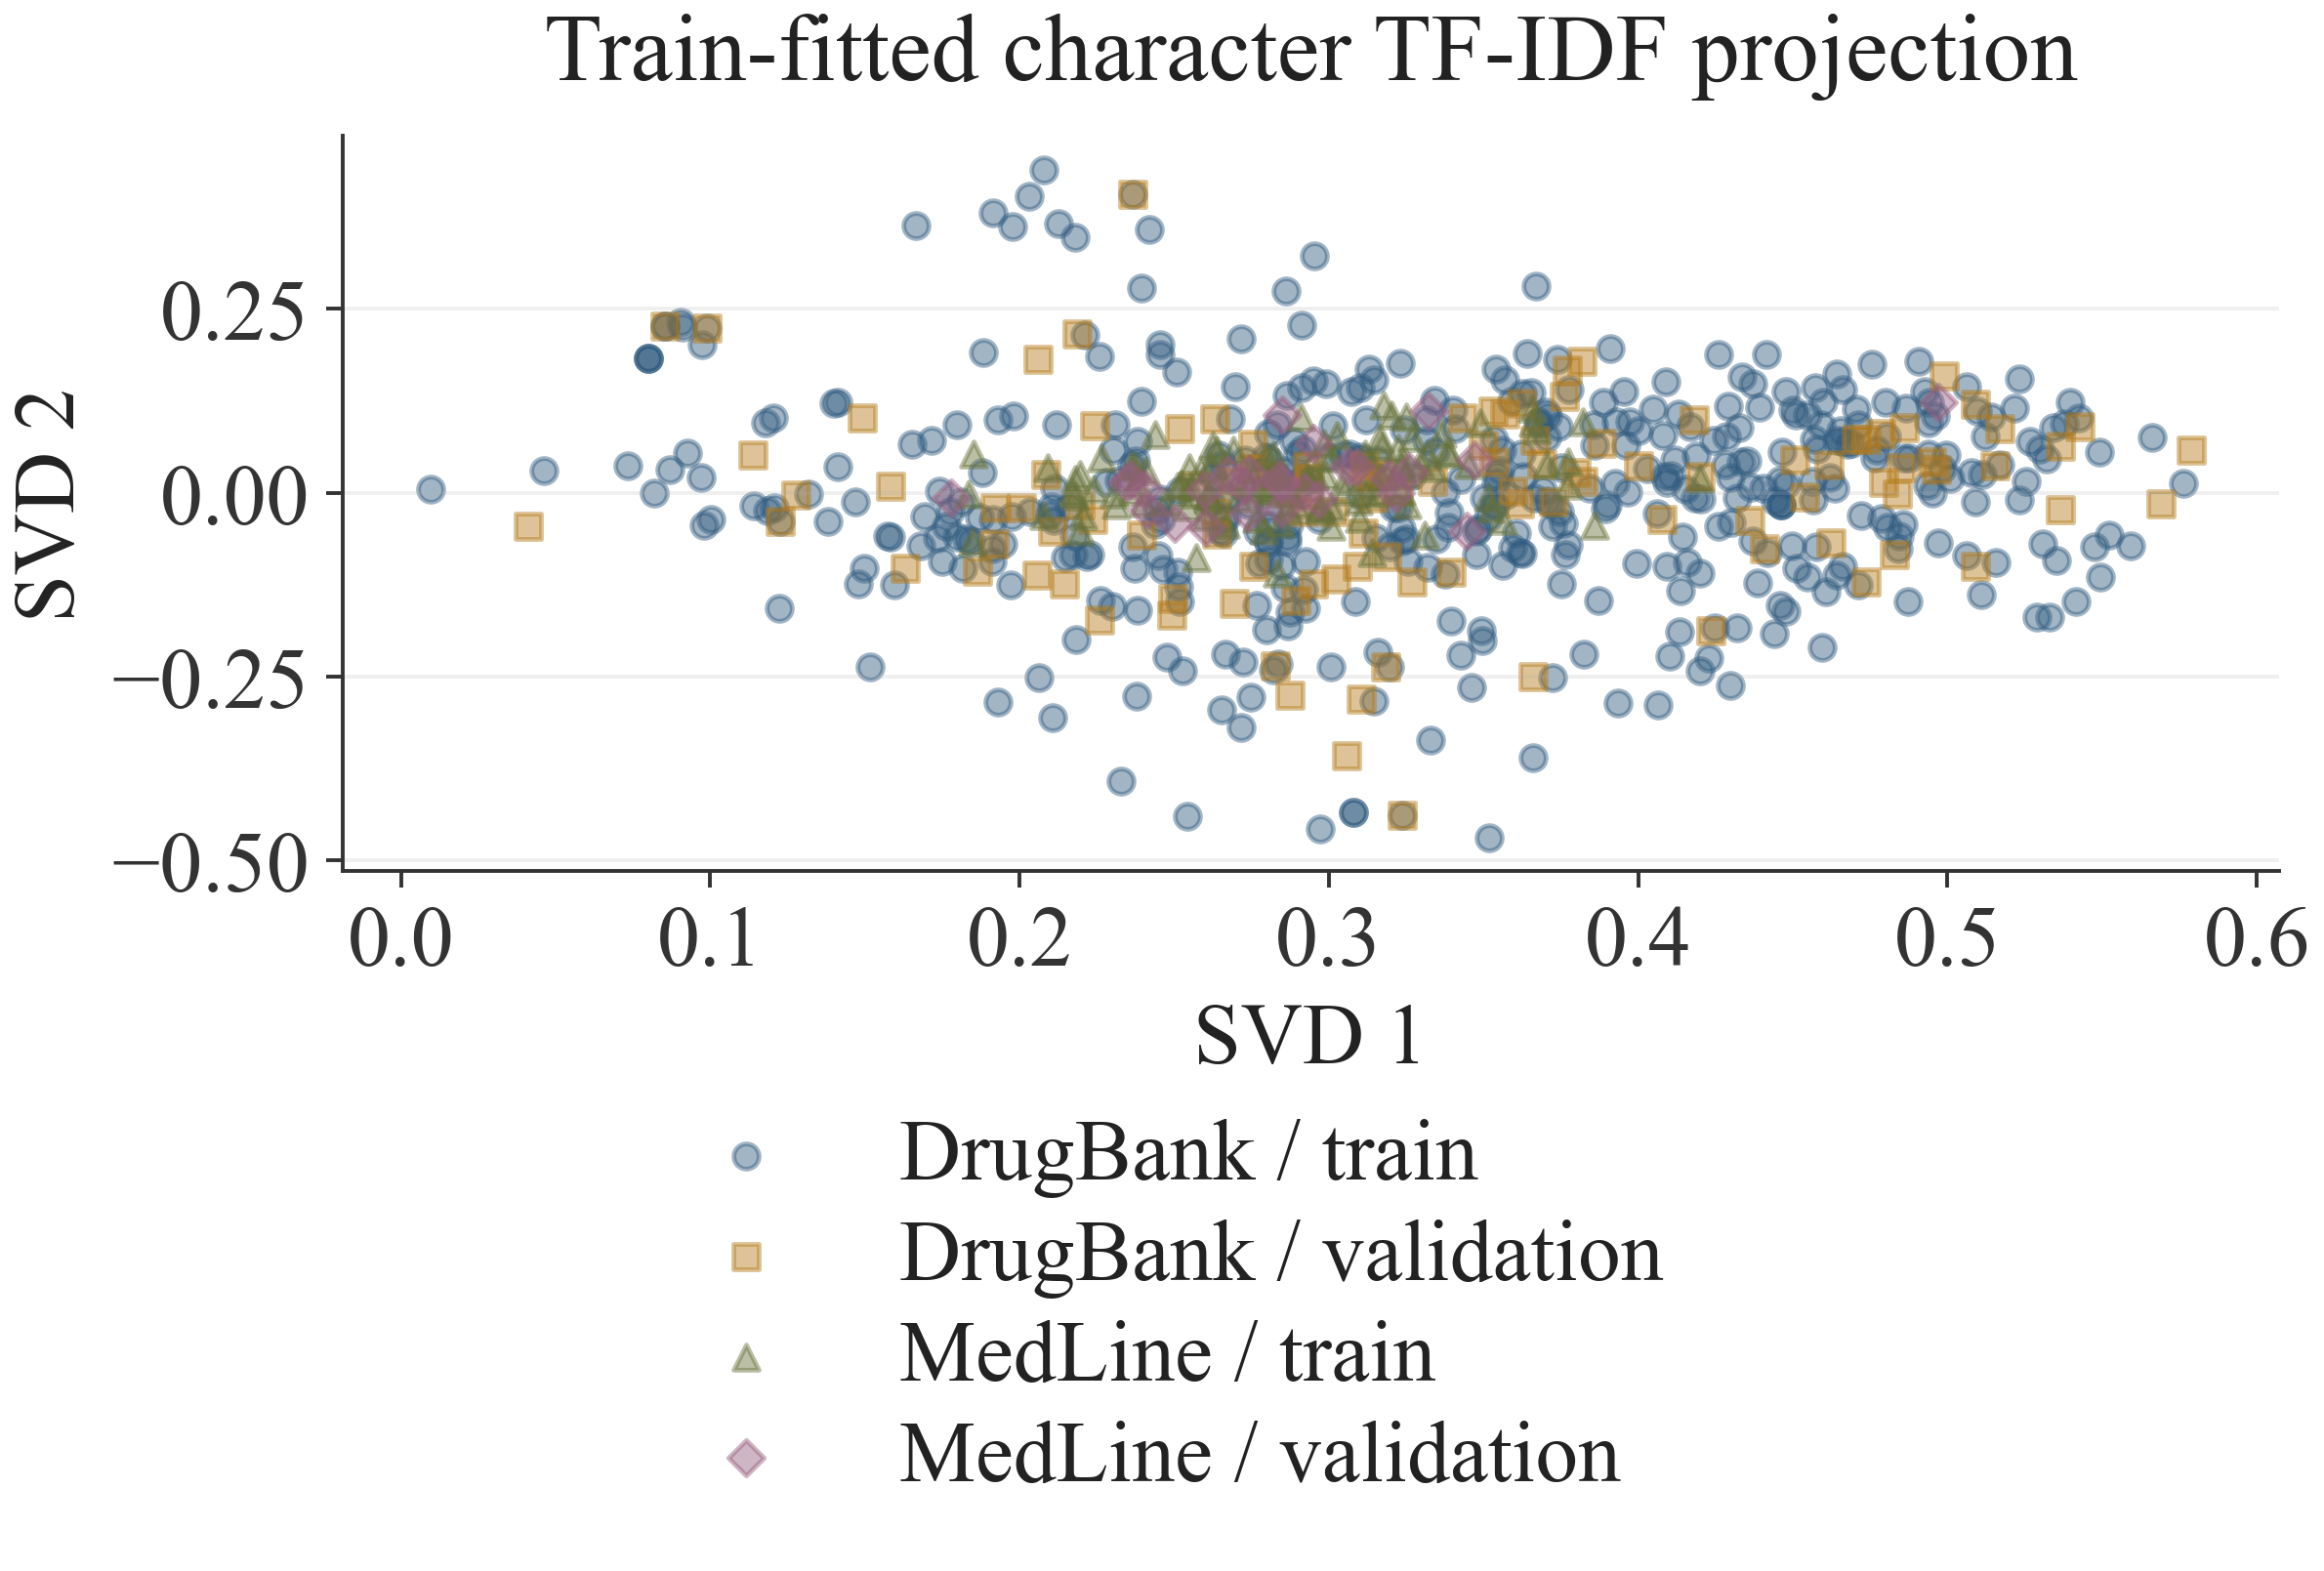

In [25]:
plot_data = projection.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.8, 4.6), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
groups = list(plot_data.groupby("Group", sort=False))
colors = [BLUE, GOLD, "#67713B", "#965F7E", "#777777", "#3B757A", "#A75936"]
for index, (group, points) in enumerate(groups):
    label = textwrap.fill(str(group), 25) if group else None
    ax.scatter(
        points["SVD 1"],
        points["SVD 2"],
        s=28,
        alpha=0.45,
        marker=["o", "s", "^", "D"][index % 4],
        color=colors[index % len(colors)],
        label=label,
    )
handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="outside lower center",
    ncol=1,
    frameon=False,
    borderaxespad=0.45,
    labelspacing=0.25,
)
ax.set_title("Train-fitted character TF-IDF projection", fontsize=20, pad=12)
ax.set_xlabel("SVD 1")
ax.set_ylabel("SVD 2")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(PROJECT_ROOT / "figures/PNG/pub_02_text_projection.png", dpi=350, facecolor="white")
fig.savefig(PROJECT_ROOT / "figures/PDF/pub_02_text_projection.pdf", dpi=350, facecolor="white")
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_02_text_projection_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

The visual projection is descriptive and substantially lossy.

33,174 Train-fit character n-grams; two components retain 3.16% of variance. Fit: 572 documents; transform: 142.

The plot is a descriptive view of lexical source/split structure.

**Scope.** Two components can retain little total variation; visual separation is not a significance test.

## Projection information retained

**Scientific question.** How much of the text representation is visible in the two-dimensional canvas?

In [26]:
result_table = projection_support.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_02_projection_support.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Train documents,Validation documents,Train-fit n-grams,Two-component variance share
572,142,33174,0.0316


The two-dimensional view retains only a small fraction of text variation.

33,174 Train-fit character n-grams; two components retain 3.16% of variance. Fit: 572 documents; transform: 142.

Low retained variance limits conclusions drawn from the scatterplot.

**Scope.** Uncentered truncated SVD geometry is not a full semantic embedding of biomedical meaning.

## Vocabulary distribution shift

**Scientific question.** How different are Train-source and Validation-source word distributions?

In [27]:
def lexical_shift(sentences, resamples=499):
    docs = sentences.groupby(["document_id", "source", "split"], as_index=False).text.agg(
        " ".join
    )
    token_lists = [re.findall("\\b\\w+\\b", t.casefold()) for t in docs.text]
    train = docs.split.eq("train").to_numpy()
    counts = Counter((t for i, l in enumerate(token_lists) if train[i] for t in l))
    vocabulary = {
        t: i for i, (t, n) in enumerate(sorted(((t, n) for t, n in counts.items() if n >= 2)))
    }
    matrix = np.zeros((len(docs), len(vocabulary) + 1), dtype=np.int32)
    for i, stream in enumerate(token_lists):
        for t, n in Counter(stream).items():
            matrix[i, vocabulary.get(t, len(vocabulary))] += n
    rng = np.random.default_rng(20260905)
    rows = []
    for reference in ["DrugBank", "MedLine"]:
        a = np.flatnonzero(train & docs.source.eq(reference).to_numpy())
        ref = matrix[a].sum(0)
        for target in ["DrugBank", "MedLine"]:
            b = np.flatnonzero(~train & docs.source.eq(target).to_numpy())
            val = matrix[b].sum(0)
            observed = jensenshannon(ref, val, base=2)
            boot = []
            for _ in range(resamples):
                boot.append(
                    jensenshannon(
                        ref, matrix[rng.choice(b, len(b), replace=True)].sum(0), base=2
                    )
                )
            rows.append(
                {
                    "Train source": reference,
                    "Validation source": target,
                    "Validation documents": len(b),
                    "Jensen-Shannon distance": observed,
                    "Bootstrap mean": np.mean(boot),
                    "Bootstrap SD": np.std(boot, ddof=1),
                }
            )
    return pd.DataFrame(rows)

In [28]:
shift_profiles = lexical_shift(development_text, resamples=499)
result_table = shift_profiles.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_02_lexical_shift.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Train source,Validation source,Validation documents,Jensen-Shannon distance,Bootstrap mean,Bootstrap SD
DrugBank,DrugBank,114,0.2944,0.3364,0.0094
DrugBank,MedLine,28,0.5442,0.5811,0.0160
MedLine,DrugBank,114,0.4982,0.5162,0.0058
MedLine,MedLine,28,0.4653,0.5122,0.0132


Jensen–Shannon distance compares both within-source and cross-source language profiles.

Base-2 Jensen–Shannon distance; vocabulary learned only from Train; rare/unseen words share an explicit unknown bucket.

Larger distances indicate greater lexical distribution mismatch under this representation.

**Scope.** Bootstrap mean/SD describe resampling sensitivity, not confidence intervals. Vocabulary loss in resamples inflates this high-dimensional distance; Train remains fixed.